# Result 3: Shakespeare language modelling

Reproduces Section 4.2 of *Were RNNs All We Needed?* (Feng et al., 2024).

## How to run this

**Runtime > Run all.** That is it, on a fresh runtime, with Mamba included. No restart.

Results are saved after every model, so if the session drops just Run all again and it picks
up where it stopped. Expect 1 to 2 hours for all four models on a T4.

Paper targets:

| Model | Test loss | Best step |
|---|---|---|
| minGRU | 1.548 | 575 |
| minLSTM | 1.555 | 625 |
| Mamba | 1.575 | 400 |
| Transformer | 1.547 | 2000 |

## Settings

In [ ]:
SMOKE = False           # True = 1 minute sanity run on tiny models, no GPU needed
INSTALL_MAMBA = True   
SAVE_TO_DRIVE = True    
DRIVE_FOLDER = "minrnn-result3"
RESET = False           # True = discard saved results
ACCEPT_PARTIAL = True   
USE_NO_DEPS = False     # only if the install leaves torch off 2.10

## Install Mamba

Left on by default. It skips itself if `mamba_ssm` is already present, so it costs nothing
on a session that already has it.

In [ ]:
import importlib, importlib.util, subprocess, sys

MAMBA_WHEEL = ("https://github.com/state-spaces/mamba/releases/download/v2.3.2.post1/"
               "mamba_ssm-2.3.2.post1%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl")
CONV1D_WHEEL = ("https://github.com/Dao-AILab/causal-conv1d/releases/download/v1.7.0/"
                "causal_conv1d-1.7.0%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl")

if not INSTALL_MAMBA:
    print("INSTALL_MAMBA is False. Skipping.")
elif importlib.util.find_spec("mamba_ssm") is not None:
    print("mamba_ssm is already installed. Skipping.")
else:
    torch_already_imported = "torch" in sys.modules

    def pip(*a):
        print(">", a[0].rsplit("/", 1)[-1])
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *a],
                           capture_output=True, text=True)
        if r.returncode:
            print(r.stdout[-1200:], r.stderr[-1200:])
        return r.returncode == 0

    ok = pip("torch==2.10.*", "--index-url", "https://download.pytorch.org/whl/cu130")
    ok = ok and pip(CONV1D_WHEEL, "--no-deps")
    ok = ok and pip(MAMBA_WHEEL, *(["--no-deps"] if USE_NO_DEPS else []))
    if ok and USE_NO_DEPS:
        ok = pip("einops", "transformers")
    if not ok:
        raise SystemExit("install failed, see the output above")

    importlib.invalidate_caches()
    version = subprocess.run([sys.executable, "-c", "import torch;print(torch.__version__)"],
                             capture_output=True, text=True).stdout.strip()
    print(f"\ntorch on disk is now {version}")

    if not version.startswith("2.10"):
        raise SystemExit("NOT 2.10. Set USE_NO_DEPS = True and Run all again.")
    if torch_already_imported:
        raise SystemExit(
            "\n  torch was already imported in this kernel, so it cannot be swapped."
        )
    print("torch had not been imported yet, so no restart is needed. Continuing.")

> torch==2.10.*
> causal_conv1d-1.7.0%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl
> mamba_ssm-2.3.2.post1%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl

torch on disk is now 2.10.0+cu130
torch had not been imported yet, so no restart is needed. Continuing.


## Setup

In [ ]:
import json, math, time, urllib.request
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

dev = "cuda" if torch.cuda.is_available() else "cpu"

OUTDIR = Path(".")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTDIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER
        OUTDIR.mkdir(parents=True, exist_ok=True)
    except ImportError:
        print("not on Colab, writing to the working directory instead")

STATE = OUTDIR / "result3_results.json"
if RESET and STATE.exists():
    STATE.unlink()

Mamba, mamba_error = None, None
try:
    from mamba_ssm import Mamba
except (ImportError, OSError) as error:
    mamba_error = str(error)

print("torch", torch.__version__, "| device =", dev)
if dev == "cuda":
    print("gpu  =", torch.cuda.get_device_name(0))
print("mamba_ssm:", "present" if Mamba else "missing, the other 3 models still run")
print("results ->", STATE)
if SMOKE:
    print("\nSMOKE MODE: tiny models, 50 steps. Set SMOKE = False for the real run.")

Mounted at /content/drive
torch 2.10.0+cu130 | device = cuda
gpu  = Tesla T4
mamba_ssm: present
results -> /content/drive/MyDrive/minrnn-result3/result3_results.json


## Data

tiny-shakespeare, character level, 90/10 split as nanoGPT prepares it. The assert checks the
exact token counts the paper reports.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
path = Path("input.txt")
if not path.exists():
    urllib.request.urlretrieve(URL, path)

text = path.read_text()
chars = sorted(set(text))
VOCAB = len(chars)
stoi = {c: i for i, c in enumerate(chars)}

data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
split = int(0.9 * len(data))
train_data, test_data = data[:split], data[split:]

assert len(train_data) == 1_003_854 and len(test_data) == 111_540, \
    f"got {len(train_data)}/{len(test_data)}, paper reports 1003854/111540"
print(f"vocab {VOCAB} | train {len(train_data):,} | test {len(test_data):,}")
print(f"random-guess loss = ln({VOCAB}) = {math.log(VOCAB):.3f}")

vocab 65 | train 1,003,854 | test 111,540
random-guess loss = ln(65) = 4.174


## minGRU and minLSTM

Log-space parallel form from Appendix B. `logsigmoid(x)` replaces `-softplus(-x)`, which is
the same quantity in fewer kernels.

In [ ]:
def g(x):
    return torch.where(x >= 0, x + 0.5, torch.sigmoid(x))


def log_g(x):
    return torch.where(x >= 0, (F.relu(x) + 0.5).log(), F.logsigmoid(x))


def scan_log(log_a, log_b):
    log_a = F.pad(log_a, (0, 0, 1, 0))
    log_b = F.pad(log_b, (0, 0, 1, 0), value=float("-inf"))
    a_star = log_a.cumsum(dim=1)
    return (a_star + torch.logcumsumexp(log_b - a_star, dim=1)).exp()[:, 1:]


class minGRU(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.to_z = nn.Linear(dim, hidden_dim, bias=False)
        self.to_h = nn.Linear(dim, hidden_dim, bias=False)
        self.to_out = nn.Linear(hidden_dim, dim, bias=False)

    def forward(self, x):
        pre_z, pre_h = self.to_z(x), self.to_h(x)
        log_z = F.logsigmoid(pre_z)
        return self.to_out(scan_log(log_z - pre_z, log_z + log_g(pre_h)))


class minLSTM(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.to_f = nn.Linear(dim, hidden_dim, bias=False)
        self.to_i = nn.Linear(dim, hidden_dim, bias=False)
        self.to_h = nn.Linear(dim, hidden_dim, bias=False)
        self.to_out = nn.Linear(hidden_dim, dim, bias=False)

    def forward(self, x):
        pre_f, pre_i, pre_h = self.to_f(x), self.to_i(x), self.to_h(x)
        log_f, log_i = F.logsigmoid(pre_f), F.logsigmoid(pre_i)
        denom = torch.logaddexp(log_f, log_i)
        return self.to_out(scan_log(log_f - denom, log_i - denom + log_g(pre_h)))

## Model

Appendix C gives the block as `Conv4 -> minRNN -> MLP` with residuals, normalization and a
downprojection. The conv is depthwise and left-padded so nothing sees the future. Mamba has
its own internal conv so it is used as the mixer directly.

Context length, MLP ratio, activation and norm placement are not stated in the paper. These
follow nanoGPT's `shakespeare_char` defaults: 256, 4x, GELU, pre-norm.

In [ ]:
class CausalConv(nn.Module):
    def __init__(self, dim, kernel=4):
        super().__init__()
        self.pad = kernel - 1
        self.conv = nn.Conv1d(dim, dim, kernel, groups=dim)

    def forward(self, x):
        y = F.pad(x.transpose(1, 2), (self.pad, 0))
        return self.conv(y).transpose(1, 2)


class Attention(nn.Module):
    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.heads, self.dropout = heads, dropout
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = (t.view(B, T, self.heads, D // self.heads).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0)
        return self.proj(y.transpose(1, 2).reshape(B, T, D))


def make_mixer(kind, dim, expansion, heads, dropout):
    if kind in ("minGRU", "minLSTM"):
        cell = minGRU if kind == "minGRU" else minLSTM
        return nn.Sequential(CausalConv(dim), cell(dim, dim * expansion))
    if kind == "Mamba":
        return Mamba(d_model=dim, d_state=16, d_conv=4, expand=expansion)
    if kind == "Transformer":
        return Attention(dim, heads, dropout)
    raise ValueError(kind)


class Block(nn.Module):
    def __init__(self, kind, dim, expansion, heads, dropout, mlp_ratio):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.mixer = make_mixer(kind, dim, expansion, heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_ratio * dim), nn.GELU(),
                                 nn.Linear(mlp_ratio * dim, dim))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.drop(self.mixer(self.norm1(x)))
        return x + self.drop(self.mlp(self.norm2(x)))


class CharLM(nn.Module):
    def __init__(self, kind, vocab, context, dim=384, layers=3, heads=6,
                 expansion=2, dropout=0.2, mlp_ratio=4):
        super().__init__()
        self.tok = nn.Embedding(vocab, dim)
        self.pos = nn.Embedding(context, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [Block(kind, dim, expansion, heads, dropout, mlp_ratio) for _ in range(layers)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False)

    def forward(self, idx, targets=None):
        pos = torch.arange(idx.shape[1], device=idx.device)
        x = self.drop(self.tok(idx) + self.pos(pos))
        for block in self.blocks:
            x = block(x)
        logits = self.head(self.norm(x))
        if targets is None:
            return logits, None
        return logits, F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

## Causality check

The most important test here. A future-token leak lowers the loss and looks like success.
This perturbs one position and asserts no earlier position's logits move.

In [ ]:
for kind in ("minGRU", "minLSTM"):
    torch.manual_seed(0)
    model = CharLM(kind, VOCAB, 32, dim=32, layers=2, heads=4, dropout=0.0).eval()
    a = torch.randint(0, VOCAB, (1, 32))
    b = a.clone()
    b[0, 16] = (b[0, 16] + 1) % VOCAB
    with torch.no_grad():
        delta = (model(a)[0] - model(b)[0]).abs()
    before, after = delta[0, :16].max().item(), delta[0, 16:].max().item()
    assert before < 1e-8 < after, f"{kind} LEAKS THE FUTURE: before={before:.2e}"
    print(f"{kind:10s} causal")

minGRU     causal
minLSTM    causal


## Training

Appendix C: AdamW 1e-3, batch 64, 5000 steps, clip 0.25, dropout 0.2, 3 layers, dim 384,
evaluated every 25 steps. Weight decay, warmup and cosine decay are not stated and follow
nanoGPT.

In [ ]:
CFG = dict(context=256, batch=64, steps=5000, eval_every=25, eval_batches=20,
           lr=1e-3, weight_decay=1e-1, clip=0.25, warmup=100, min_lr=1e-4,
           dim=384, layers=3, heads=6, expansion=2, dropout=0.2, mlp_ratio=4)
if SMOKE:
    CFG.update(context=64, batch=8, steps=50, eval_every=10, eval_batches=2,
               dim=64, layers=2, heads=4)

SAVE_EVERY_EVALS = 5


def get_batch(source, cfg, generator=None):
    i = torch.randint(len(source) - cfg["context"] - 1, (cfg["batch"],), generator=generator)
    x = torch.stack([source[j:j + cfg["context"]] for j in i])
    y = torch.stack([source[j + 1:j + 1 + cfg["context"]] for j in i])
    return x.to(dev), y.to(dev)


@torch.no_grad()
def evaluate(model, cfg):
    model.eval()
    out = {}
    for name, source in (("train", train_data), ("test", test_data)):
        gen = torch.Generator().manual_seed(1234)
        out[name] = sum(model(*get_batch(source, cfg, gen))[1].item()
                        for _ in range(cfg["eval_batches"])) / cfg["eval_batches"]
    model.train()
    return out


def lr_at(step, cfg):
    if step < cfg["warmup"]:
        return cfg["lr"] * (step + 1) / cfg["warmup"]
    t = (step - cfg["warmup"]) / max(1, cfg["steps"] - cfg["warmup"])
    return cfg["min_lr"] + 0.5 * (1 + math.cos(math.pi * t)) * (cfg["lr"] - cfg["min_lr"])


def train(kind, cfg, seed=0, on_update=None):
    torch.manual_seed(seed)
    model = CharLM(kind, VOCAB, cfg["context"], dim=cfg["dim"], layers=cfg["layers"],
                   heads=cfg["heads"], expansion=cfg["expansion"],
                   dropout=cfg["dropout"], mlp_ratio=cfg["mlp_ratio"]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    params = sum(p.numel() for p in model.parameters())
    history, best, best_step, start = [], float("inf"), 0, time.time()

    def record(complete):
        return {"model": kind, "best_test_loss": best, "best_step": best_step,
                "final_test_loss": history[-1][2], "steps_done": history[-1][0],
                "minutes": (time.time() - start) / 60, "params": params,
                "complete": complete, "history": history}

    for step in range(cfg["steps"] + 1):
        if step % cfg["eval_every"] == 0:
            losses = evaluate(model, cfg)
            history.append((step, losses["train"], losses["test"]))
            if losses["test"] < best:
                best, best_step = losses["test"], step
            if on_update and len(history) % SAVE_EVERY_EVALS == 0:
                on_update(record(False))
            if step % (cfg["eval_every"] * 20) == 0:
                elapsed = time.time() - start
                eta = elapsed / step * (cfg["steps"] - step) / 60 if step else None
                tail = f"  eta {eta:4.1f} min" if eta is not None else ""
                print(f"  step {step:5d}/{cfg['steps']}  test {losses['test']:.4f}  "
                      f"best {best:.4f} @ {best_step}{tail}")
        for group in opt.param_groups:
            group["lr"] = lr_at(step, cfg)
        x, y = get_batch(train_data, cfg)
        opt.zero_grad(set_to_none=True)
        model(x, y)[1].backward()
        nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
        opt.step()

    return record(True)

## Run

Roughly 20 to 40 minutes per model on a T4. Results are written to disk after each one, so
re-running skips whatever already finished.

In [ ]:
MODELS = ["minGRU", "minLSTM", "Transformer"]
if Mamba is not None and dev == "cuda":
    MODELS.insert(2, "Mamba")
else:
    print("Mamba skipped:", mamba_error or "needs CUDA")

PATIENCE_EVALS = 20

state = json.loads(STATE.read_text()) if STATE.exists() else {}


def save_state():
    STATE.write_text(json.dumps(state))


def usable(rec):
    if rec.get("complete"):
        return True, "complete"
    if not ACCEPT_PARTIAL or not rec.get("history"):
        return False, "partial"
    losses = [h[2] for h in rec["history"]]
    since_best = len(losses) - losses.index(min(losses)) - 1
    if since_best >= PATIENCE_EVALS:
        return True, f"partial but {since_best} evals past its minimum, accepted"
    return False, "partial and still improving"


for kind in MODELS:
    if kind in state:
        ok, why = usable(state[kind])
        print(f"{kind}: {why}")
        if ok:
            continue
    print(f"\n=== {kind} ===")
    try:
        state[kind] = train(kind, CFG,
                            on_update=lambda rec, k=kind: (state.__setitem__(k, rec), save_state()))
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print(f"{kind}: out of memory, skipped")
        continue
    save_state()
    r = state[kind]
    print(f"  best {r['best_test_loss']:.4f} @ step {r['best_step']}  "
          f"({r['params'] / 1e6:.2f}M params, {r['minutes']:.1f} min)")
    if dev == "cuda":
        torch.cuda.empty_cache()

results = [state[k] for k in MODELS if k in state and usable(state[k])[0]]
print(f"\n{len(results)} of {len(MODELS)} models usable, saved to {STATE}")


=== minGRU ===
  step     0/5000  test 4.3396  best 4.3396 @ 0
  step   500/5000  test 1.6334  best 1.6334 @ 500  eta 34.0 min
  step  1000/5000  test 1.5054  best 1.5011 @ 975  eta 30.6 min
  step  1500/5000  test 1.4978  best 1.4786 @ 1400  eta 26.9 min
  step  2000/5000  test 1.5020  best 1.4786 @ 1400  eta 23.1 min
  step  2500/5000  test 1.5525  best 1.4786 @ 1400  eta 19.3 min
  step  3000/5000  test 1.5777  best 1.4786 @ 1400  eta 15.4 min
  step  3500/5000  test 1.6121  best 1.4786 @ 1400  eta 11.6 min
  step  4000/5000  test 1.6487  best 1.4786 @ 1400  eta  7.7 min
  step  4500/5000  test 1.6814  best 1.4786 @ 1400  eta  3.9 min
  step  5000/5000  test 1.7116  best 1.4786 @ 1400  eta  0.0 min
  best 1.4786 @ step 1400  (6.36M params, 38.6 min)

=== minLSTM ===
  step     0/5000  test 4.2546  best 4.2546 @ 0
  step   500/5000  test 1.6107  best 1.6107 @ 500  eta 41.2 min
  step  1000/5000  test 1.5043  best 1.5043 @ 1000  eta 36.4 min
  step  1500/5000  test 1.4880  best 1.488

## Comparison and curves

,model,complete,best_loss,paper_loss,diff_%,best_step,paper_step,final_loss,params_M,minutes
0,minGRU,True,1.4786,1.548,-4.5,1400,575,1.7116,6.36,38.6
1,minLSTM,True,1.4880,1.555,-4.3,1500,625,1.7138,7.24,45.2
2,Mamba,True,1.5201,1.575,-3.5,825,400,2.2176,6.59,36.4
3,Transformer,True,1.4711,1.547,-4.9,4900,2000,1.4765,5.47,27.5


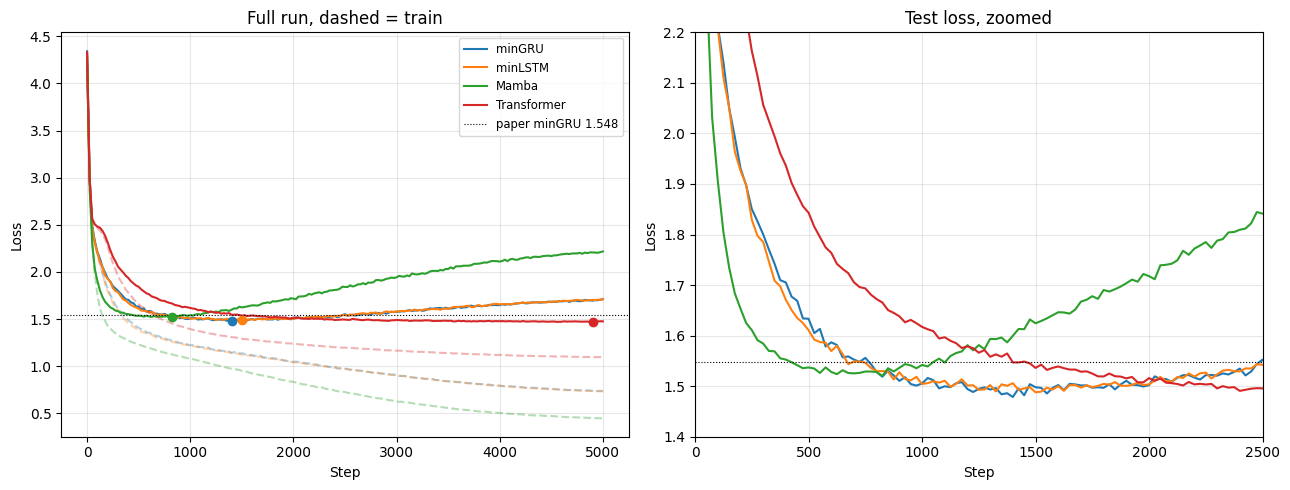

saved to /content/drive/MyDrive/minrnn-result3


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

PAPER = {"minGRU": (1.548, 575), "minLSTM": (1.555, 625),
         "Mamba": (1.575, 400), "Transformer": (1.547, 2000)}

rows = []
for r in results:
    loss, step = PAPER[r["model"]]
    rows.append({"model": r["model"], "complete": r.get("complete", False), "best_loss": round(r["best_test_loss"], 4),
                 "paper_loss": loss,
                 "diff_%": round(100 * (r["best_test_loss"] - loss) / loss, 1),
                 "best_step": r["best_step"], "paper_step": step,
                 "final_loss": round(r["final_test_loss"], 4),
                 "params_M": round(r["params"] / 1e6, 2),
                 "minutes": round(r["minutes"], 1)})
table = pd.DataFrame(rows)
table.to_csv(OUTDIR / "result3_shakespeare.csv", index=False)
display(table)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for r in results:
    steps, tr, te = zip(*r["history"])
    line, = axes[0].plot(steps, te, label=r["model"])
    axes[0].plot(steps, tr, color=line.get_color(), alpha=0.35, linestyle="--")
    axes[0].scatter([r["best_step"]], [r["best_test_loss"]], color=line.get_color(), zorder=5)
    axes[1].plot(steps, te, label=r["model"])

for ax, title in ((axes[0], "Full run, dashed = train"), (axes[1], "Test loss, zoomed")):
    ax.axhline(1.548, color="black", linewidth=0.8, linestyle=":", label="paper minGRU 1.548")
    ax.set(title=title, xlabel="Step", ylabel="Loss")
    ax.grid(alpha=0.3)
axes[1].set_xlim(0, 2500)
axes[1].set_ylim(1.4, 2.2)
axes[0].legend(fontsize="small")

fig.tight_layout()
fig.savefig(OUTDIR / "result3_shakespeare.png", dpi=180, bbox_inches="tight")
plt.show()
print("saved to", OUTDIR)